In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, k, e
from scipy.signal import correlate
from math import erfc

from optic.comm.modulation import modulateGray, demodulateGray
from optic.dsp.core import lowPassFIR, firFilter, upsample
from optic.models.devices import mzm
from optic.plot import eyediagram
from optic.utils import parameters

In [12]:
# 1. Khai báo bộ đối tượng tham số
param = parameters() 

# Tham số tín hiệu & Thời gian (PAM4)
param.Rs = 10e9          # Tốc độ ký hiệu (Symbol rate): 10 GBaud -> Bitrate = 20 Gbps (PAM4 mang 2 bits/symb)
param.SpS = 16           # Số mẫu trên 1 ký hiệu (Samples per symbol)
param.Fs = param.Rs * param.SpS  # Tần số lấy mẫu (160 GHz)
param.Nbits = 2**14      # Tổng số bit mô phỏng (16,384 bits - bắt buộc là số chẵn cho PAM4)

# Tham số Bộ điều chế Quang MZM (Khối phát)
param.Vpi = 2.0          # Điện áp Vpi = 2V
param.Vb = -1.0          # Điện áp Bias = -1V
P_tx_dBm = 0             # Công suất quang phát: 0 dBm (1 mW)
P_tx_mW = 10**(P_tx_dBm/10)

# Tham số Kênh truyền Sợi quang (Fiber Channel)
param.L = 20             # Chiều dài sợi quang: L km
param.alpha = 0.2        # Hệ số suy hao: 0.2 dB/km
param.D = 18.0           # Hệ số tán sắc sắc thể: 18 ps/nm/km
param.lamda = 1550e-9    # Bước sóng hoạt động: 1550 nm

# Tham số Bộ thu Quang Photodiode & Nhiễu (Receiver)
param.R = 0.85           # Trách nhiệm quang (Responsivity) = 0.85 A/W
param.B = 0.75 * param.Rs # Băng thông bộ thu = 7.5 GHz
T_temp = 300             # Nhiệt độ môi trường = 300 K
R_load = 50              # Trở kháng tải = 50 Ohm

print("==================================================")
print("     BỘ THAM SỐ MÔ PHỎNG HỆ THỐNG IM-DD (PAM4)")
print("==================================================")
print(f"• Tốc độ ký hiệu (Symbol rate):  {param.Rs/1e9:.1f} GBaud")
print(f"• Tốc độ bit tương ứng (Bitrate): {2 * param.Rs/1e9:.1f} Gbps")
print(f"• Tần số lấy mẫu (Fs):           {param.Fs/1e9:.1f} GHz")
print(f"• Bước sóng quang (wavelength):  {param.lamda*1e9:.0f} nm")
print(f"• Chiều dài sợi quang (L):       {param.L} km")
print(f"• Suy hao sợi quang (alpha):     {param.alpha} dB/km")
print(f"• Tán sắc sắc thể (D):          {param.D} ps/nm/km")
print(f"• Băng thông bộ thu (B):         {param.B/1e9:.2f} GHz")
print("==================================================")

     BỘ THAM SỐ MÔ PHỎNG HỆ THỐNG IM-DD (PAM4)
• Tốc độ ký hiệu (Symbol rate):  10.0 GBaud
• Tốc độ bit tương ứng (Bitrate): 20.0 Gbps
• Tần số lấy mẫu (Fs):           160.0 GHz
• Bước sóng quang (wavelength):  1550 nm
• Chiều dài sợi quang (L):       20 km
• Suy hao sợi quang (alpha):     0.2 dB/km
• Tán sắc sắc thể (D):          18.0 ps/nm/km
• Băng thông bộ thu (B):         7.50 GHz



--------------------------------------------------
1. KẾT QUẢ SỐ LIỆU TÍNH TOÁN KHỐI PHÁT PAM4
--------------------------------------------------
• Công suất quang phát đỉnh (Peak Tx Power): 0.962 mW
• Công suất quang phát trung bình:           0.502 mW (-2.99 dBm)


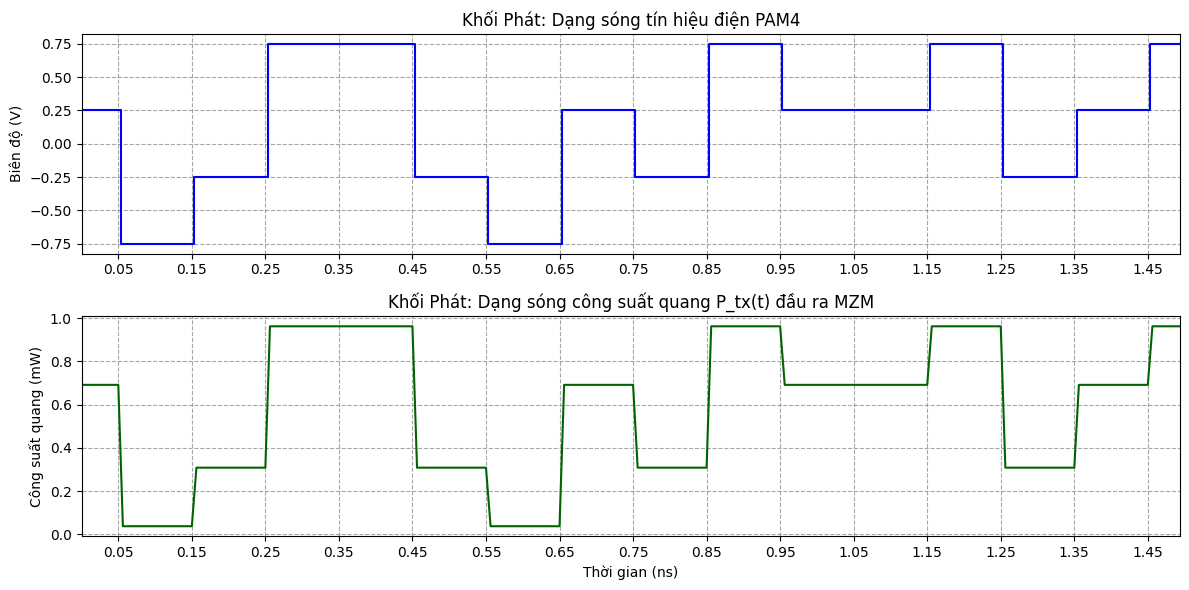

In [13]:
# --- QUÁ TRÌNH XỬ LÝ KHỐI PHÁT PAM4 ---
# 1. Tạo chuỗi bit ngẫu nhiên
bitsTx = np.random.randint(0, 2, param.Nbits)

# 2. Điều chế chuỗi bit thành tín hiệu điện PAM4 (4 mức: Gray mapping)
symbTx = modulateGray(bitsTx, 4, 'pam') # M=4 cho PAM4
symbUp = upsample(symbTx, param.SpS)
p = np.ones(param.SpS) / np.sqrt(param.SpS)
sigTx_elec = firFilter(p, symbUp)

# 3. Mã hóa tín hiệu điện sang dạng sóng quang qua MZM
Ai = np.sqrt(P_tx_mW * 1e-3)
E_tx = mzm(Ai, sigTx_elec, param)

# --- TÍNH TOÁN SỐ LIỆU KHỐI PHÁT ---
P_tx_optical = np.abs(E_tx)**2
P_tx_avg = np.mean(P_tx_optical)
P_tx_avg_dBm = 10 * np.log10(P_tx_avg / 1e-3)

print("\n--------------------------------------------------")
print("1. KẾT QUẢ SỐ LIỆU TÍNH TOÁN KHỐI PHÁT PAM4")
print("--------------------------------------------------")
print(f"• Công suất quang phát đỉnh (Peak Tx Power): {np.max(P_tx_optical)*1e3:.3f} mW")
print(f"• Công suất quang phát trung bình:           {P_tx_avg*1e3:.3f} mW ({P_tx_avg_dBm:.2f} dBm)")

# --- VẼ ĐỒ THỊ DẠNG SÓNG KHỐI PHÁT ---
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
N_simulate = 15 * param.SpS
t_ns = np.arange(N_simulate) / param.Fs * 1e9
Tsym_ns = (1 / param.Rs) * 1e9  
sym_ticks = np.arange(0.05, t_ns[-1] + Tsym_ns/2, Tsym_ns)

ax[0].step(t_ns, sigTx_elec[:N_simulate], color='blue', where='mid')
ax[0].set_title("Khối Phát: Dạng sóng tín hiệu điện PAM4")
ax[0].set_ylabel("Biên độ (V)")
ax[0].grid(True)

ax[1].plot(t_ns, P_tx_optical[:N_simulate]*1e3, color='darkgreen')
ax[1].set_title("Khối Phát: Dạng sóng công suất quang P_tx(t) đầu ra MZM")
ax[1].set_xlabel("Thời gian (ns)")
ax[1].set_ylabel("Công suất quang (mW)")
ax[1].grid(True)

for a in ax:
    a.set_xticks(sym_ticks)
    a.set_xlim([0, t_ns[-1]])
    a.grid(True, which='both', linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()
plt.show()


--------------------------------------------------
2. KẾT QUẢ SỐ LIỆU KÊNH TRUYỀN SỢI QUANG
--------------------------------------------------
• Suy hao tổng của cự ly 20 km:             4.00 dB
• Công suất quang thu được tại cuối sợi:    0.2000 mW (-6.99 dBm)
• Công suất quang thu đỉnh (Peak Rx Power): 0.660 mW


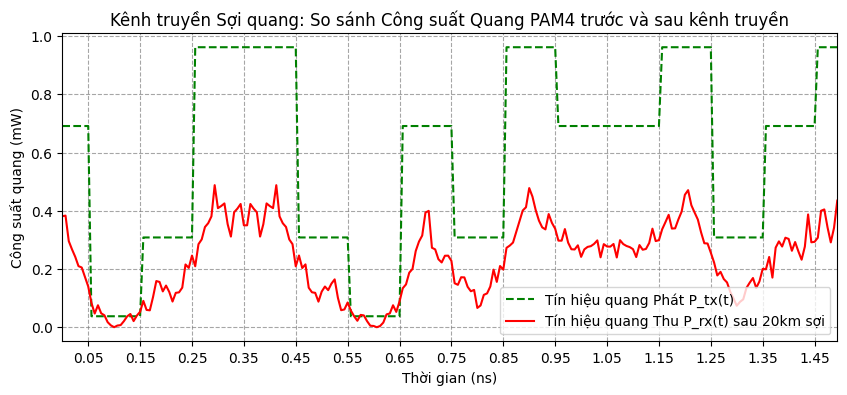

In [19]:
# --- QUÁ TRÌNH XỬ LÝ KÊNH TRUYỀN SỢI QUANG ---
# 1. Tính toán tham số vật lý của sợi quang
alpha_m = param.alpha / (10 * np.log10(np.e) * 1e3) # dB/km -> 1/m
beta2 = -(param.lamda**2 / (2 * np.pi * c)) * (param.D * 1e-6) # s^2/m
Total_Loss_dB = param.alpha * param.L

# 2. Truyền tín hiệu quang trong miền tần số (Tán sắc & Suy hao)
N_samples = len(E_tx)
freq = np.fft.fftfreq(N_samples, 1/param.Fs)
omega = 2 * np.pi * freq
H_fiber = np.exp(-alpha_m * (param.L * 1e3) / 2) * np.exp(+1j * (beta2 / 2) * (omega**2) * (param.L * 1e3))
E_rx_optical = np.fft.ifft(np.fft.fft(E_tx) * H_fiber)

# --- TÍNH TOÁN SỐ LIỆU KÊNH TRUYỀN ---
P_rx_optical = np.abs(E_rx_optical)**2
P_rx_avg = np.mean(P_rx_optical)
P_rx_avg_dBm = 10 * np.log10(P_rx_avg / 1e-3)

print("\n--------------------------------------------------")
print("2. KẾT QUẢ SỐ LIỆU KÊNH TRUYỀN SỢI QUANG")
print("--------------------------------------------------")
print(f"• Suy hao tổng của cự ly {param.L} km:             {Total_Loss_dB:.2f} dB")
print(f"• Công suất quang thu được tại cuối sợi:    {P_rx_avg*1e3:.4f} mW ({P_rx_avg_dBm:.2f} dBm)")
print(f"• Công suất quang thu đỉnh (Peak Rx Power): {np.max(P_rx_optical)*1e3:.3f} mW")

# --- VẼ ĐỒ THỊ SO SÁNH KÊNH TRUYỀN ---
plt.figure(figsize=(10, 4))
plt.plot(t_ns, P_tx_optical[:N_simulate]*1e3, label='Tín hiệu quang Phát P_tx(t)', color='green', linestyle='--')
plt.plot(t_ns, P_rx_optical[:N_simulate]*1e3, label=f'Tín hiệu quang Thu P_rx(t) sau {param.L}km sợi', color='red')
plt.title("Kênh truyền Sợi quang: So sánh Công suất Quang PAM4 trước và sau kênh truyền")
plt.xlabel("Thời gian (ns)")
plt.ylabel("Công suất quang (mW)")
plt.legend()
plt.grid(True)
for a in plt.gcf().axes:
    a.set_xticks(sym_ticks)
    a.set_xlim([0, t_ns[-1]])
    a.grid(True, which='both', linestyle='--', alpha=0.7, color='gray')
plt.show()

In [15]:
# ==========================================
# TÍNH CHIỀU DÀI SUY HAO VÀ CHIỀU DÀI TÁN SẮC
# ==========================================
# 1. Chiều dài suy hao L_alpha
alpha_km = param.alpha / (10 * np.log10(np.e))  # 1/km
L_alpha = 1 / alpha_km                          # km

# 2. Chiều dài tán sắc L_D cho PAM4
T0 = 1 / param.Rs                               # Thời lượng 1 ký hiệu PAM4 (s)
L_disp_m = (T0**2) / np.abs(beta2)              # m
L_disp_km = L_disp_m / 1e3                      # km

print("--------------------------------------------------")
print("PHÂN TÍCH ĐẶC TÍNH KÊNH TRUYỀN SỢI QUANG (PAM4)")
print("--------------------------------------------------")
print(f"• Chiều dài suy hao (L_alpha): {L_alpha:.2f} km")
print(f"• Hệ số GVD (beta2):         {beta2*1e27:.2f} (ps)^2/km")
print(f"• Chiều dài tán sắc (L_D):     {L_disp_km:.2f} km")
print("--------------------------------------------------")

--------------------------------------------------
PHÂN TÍCH ĐẶC TÍNH KÊNH TRUYỀN SỢI QUANG (PAM4)
--------------------------------------------------
• Chiều dài suy hao (L_alpha): 21.71 km
• Hệ số GVD (beta2):         -22.96 (ps)^2/km
• Chiều dài tán sắc (L_D):     435.58 km
--------------------------------------------------



--------------------------------------------------
3. KẾT QUẢ SỐ LIỆU KHỐI THU & NHIỄU (PAM4)
--------------------------------------------------
• Dòng quang điện trung bình (I_dc):         170.01 uA
• Độ lệch chuẩn Nhiễu hạt (Shot noise):      0.6392 uA
• Độ lệch chuẩn Nhiễu nhiệt (Thermal noise):  1.5764 uA
• Tỷ số Tín hiệu trên Nhiễu điện (SNR_el):   36.69 dB


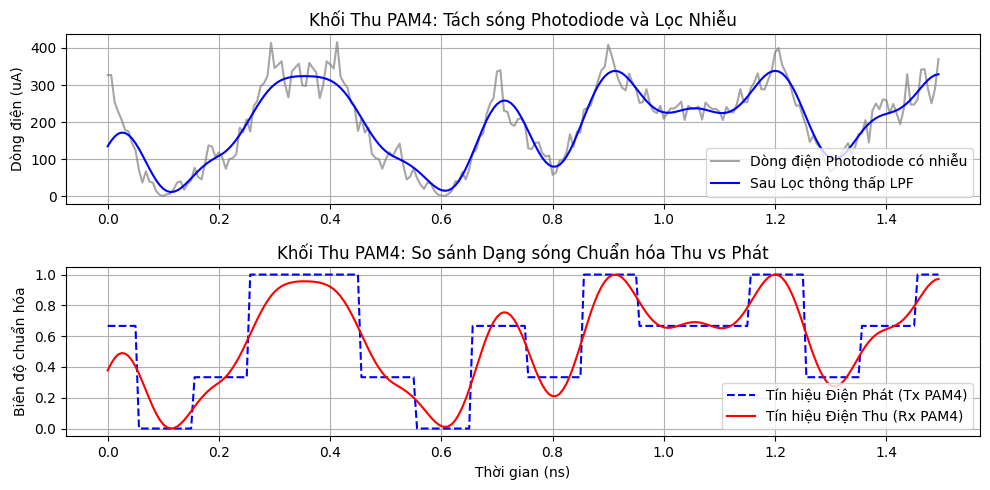


--------------------------------------------------
4. ĐÁNH GIÁ EYE DIAGRAM & TÍNH TỶ LỆ LỖI BIT (BER)
--------------------------------------------------


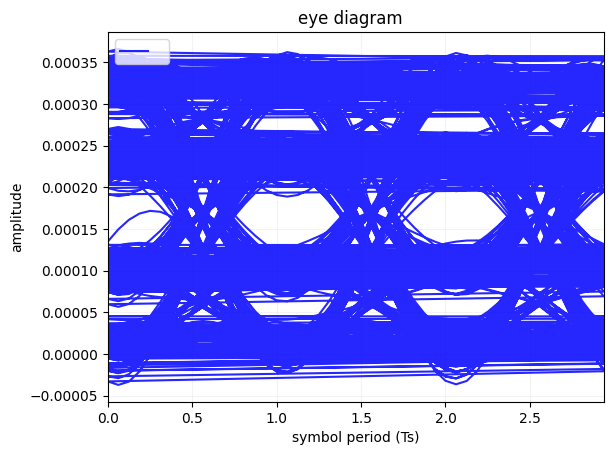

----- Thông số Eye Diagram PAM4 -----
• Mức dòng trung bình I0 = 9.86 uA | I1 = 101.81 uA | I2 = 234.21 uA | I3 = 326.72 uA
• Ngưỡng quyết định 1 (Id1 - Mắt dưới): 55.44 uA (Q1 = 2.9888)
• Ngưỡng quyết định 2 (Id2 - Mắt giữa): 166.89 uA (Q2 = 4.1951)
• Ngưỡng quyết định 3 (Id3 - Mắt trên): 280.05 uA (Q3 = 2.8568)
• HỆ SỐ Q-FACTOR TRUNG BÌNH = 3.3469

---------- THÔNG SỐ BER ----------
• Tổng số bit phát = 16384
• Tổng số bit lỗi đếm được = 7628
• Tỷ lệ lỗi bit thực tế (BER) = 4.65576172e-01
• Tỷ lệ lỗi bit lý thuyết (Pb) = 3.06456791e-04


In [18]:
# --- QUÁ TRÌNH XỬ LÝ KHỐI THU PAM4 ---
# 1. Tách sóng quang thành Dòng điện (Photodiode PIN)
Ip = param.R * P_rx_optical

# 2. Thêm Nhiễu hạt (Shot noise) và Nhiễu nhiệt (Thermal noise)
sigma2_shot = 2 * e * np.mean(Ip) * param.B
noise_shot = np.random.normal(0, np.sqrt(sigma2_shot), N_samples)

sigma2_thermal = (4 * k * T_temp / R_load) * param.B
noise_thermal = np.random.normal(0, np.sqrt(sigma2_thermal), N_samples)

I_rx_noisy = Ip + noise_shot + noise_thermal

# 3. Bộ lọc thông thấp LPF loại bỏ nhiễu cao tần
h_lpf = lowPassFIR(fc=0.75*param.Rs, fa=param.Fs, N=64)
I_filt = firFilter(h_lpf, I_rx_noisy)

SNR_rx = 10 * np.log10(np.var(Ip) / (sigma2_shot + sigma2_thermal))

print("\n--------------------------------------------------")
print("3. KẾT QUẢ SỐ LIỆU KHỐI THU & NHIỄU (PAM4)")
print("--------------------------------------------------")
print(f"• Dòng quang điện trung bình (I_dc):         {np.mean(Ip)*1e6:.2f} uA")
print(f"• Độ lệch chuẩn Nhiễu hạt (Shot noise):      {np.sqrt(sigma2_shot)*1e6:.4f} uA")
print(f"• Độ lệch chuẩn Nhiễu nhiệt (Thermal noise):  {np.sqrt(sigma2_thermal)*1e6:.4f} uA")
print(f"• Tỷ số Tín hiệu trên Nhiễu điện (SNR_el):   {SNR_rx:.2f} dB")

# --- VẼ ĐỒ THỊ DẠNG SÓNG THU ---
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(t_ns, I_rx_noisy[:N_simulate]*1e6, color='gray', alpha=0.7, label='Dòng điện Photodiode có nhiễu')
ax[0].plot(t_ns, I_filt[:N_simulate]*1e6, color='blue', linewidth=1.5, label='Sau Lọc thông thấp LPF')
ax[0].set_title("Khối Thu PAM4: Tách sóng Photodiode và Lọc Nhiễu")
ax[0].set_ylabel("Dòng điện (uA)")
ax[0].legend()
ax[0].grid(True)

sigTx_norm = (sigTx_elec[:N_simulate] - np.min(sigTx_elec[:N_simulate])) / np.ptp(sigTx_elec[:N_simulate])
I_filt_norm = (I_filt[:N_simulate] - np.min(I_filt[:N_simulate])) / np.ptp(I_filt[:N_simulate])
ax[1].plot(t_ns, sigTx_norm, label='Tín hiệu Điện Phát (Tx PAM4)', linestyle='--', color='blue')
ax[1].plot(t_ns, I_filt_norm, label='Tín hiệu Điện Thu (Rx PAM4)', color='red')
ax[1].set_title("Khối Thu PAM4: So sánh Dạng sóng Chuẩn hóa Thu vs Phát")
ax[1].set_xlabel("Thời gian (ns)")
ax[1].set_ylabel("Biên độ chuẩn hóa")
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()

# --- ĐÁNH GIÁ KẾT QUẢ: BIỂU ĐỒ MẮT PAM4 (3 MẮT) & TÍNH 3 NGƯỠNG QỦYẾT ĐỊNH ---
print("\n--------------------------------------------------")
print("4. ĐÁNH GIÁ EYE DIAGRAM & TÍNH TỶ LỆ LỖI BIT (BER)")
print("--------------------------------------------------")

# Biểu đồ mắt PAM4
eyediagram(I_filt, 1000 * param.SpS, param.SpS, n=3)
plt.show()

# Lấy mẫu tín hiệu tại vị trí giữa các ký hiệu
I_Rx = I_filt[0::param.SpS][:len(symbTx)]

# Phân loại 4 mức ký hiệu PAM4 gốc phát đi
levels_tx = np.sort(np.unique(symbTx))

# Tính giá trị trung bình và độ lệch chuẩn của 4 mức tín hiệu thu được
I_means = [np.mean(I_Rx[symbTx == lvl]) for lvl in levels_tx]
I_stds  = [np.std(I_Rx[symbTx == lvl])  for lvl in levels_tx]

# Tính 3 ngưỡng quyết định tối ưu cho PAM4 (Id1, Id2, Id3)
Id1 = (I_stds[1]*I_means[0] + I_stds[0]*I_means[1]) / (I_stds[0] + I_stds[1])
Id2 = (I_stds[2]*I_means[1] + I_stds[1]*I_means[2]) / (I_stds[1] + I_stds[2])
Id3 = (I_stds[3]*I_means[2] + I_stds[2]*I_means[3]) / (I_stds[2] + I_stds[3])

# Tính hệ số Q cho 3 mắt (Mắt dưới, Mắt giữa, Mắt trên)
Q1 = (I_means[1] - I_means[0]) / (I_stds[0] + I_stds[1])
Q2 = (I_means[2] - I_means[1]) / (I_stds[1] + I_stds[2])
Q3 = (I_means[3] - I_means[2]) / (I_stds[2] + I_stds[3])
Q_avg = np.mean([Q1, Q2, Q3])

print('----- Thông số Eye Diagram PAM4 -----')
print(f'• Mức dòng trung bình I0 = {I_means[0]*1e6:.2f} uA | I1 = {I_means[1]*1e6:.2f} uA | I2 = {I_means[2]*1e6:.2f} uA | I3 = {I_means[3]*1e6:.2f} uA')
print(f'• Ngưỡng quyết định 1 (Id1 - Mắt dưới): {Id1*1e6:.2f} uA (Q1 = {Q1:.4f})')
print(f'• Ngưỡng quyết định 2 (Id2 - Mắt giữa): {Id2*1e6:.2f} uA (Q2 = {Q2:.4f})')
print(f'• Ngưỡng quyết định 3 (Id3 - Mắt trên): {Id3*1e6:.2f} uA (Q3 = {Q3:.4f})')
print(f'• HỆ SỐ Q-FACTOR TRUNG BÌNH = {Q_avg:.4f}\n')

# Giải điều chế PAM4 thu được chuỗi bitsRx
bitsRx = demodulateGray(I_Rx, 4, 'pam')

# Tính đếm số bit lỗi và BER
err = np.logical_xor(bitsRx, bitsTx)
BER = np.mean(err)

# Xác suất lỗi bit lý thuyết cho PAM4 theo Q-factor trung bình
Pb = (3/8) * erfc(Q_avg / np.sqrt(2))

print('---------- THÔNG SỐ BER ----------')
print(f'• Tổng số bit phát = {len(bitsTx)}')
print(f'• Tổng số bit lỗi đếm được = {err.sum()}')
print(f'• Tỷ lệ lỗi bit thực tế (BER) = {BER:.8e}')
print(f'• Tỷ lệ lỗi bit lý thuyết (Pb) = {Pb:.8e}')


--------------------------------------------------
5. KHẢO SÁT TỶ LỆ LỖI BIT (BER) PAM4 THEO CỰ LY SỢI QUANG
--------------------------------------------------


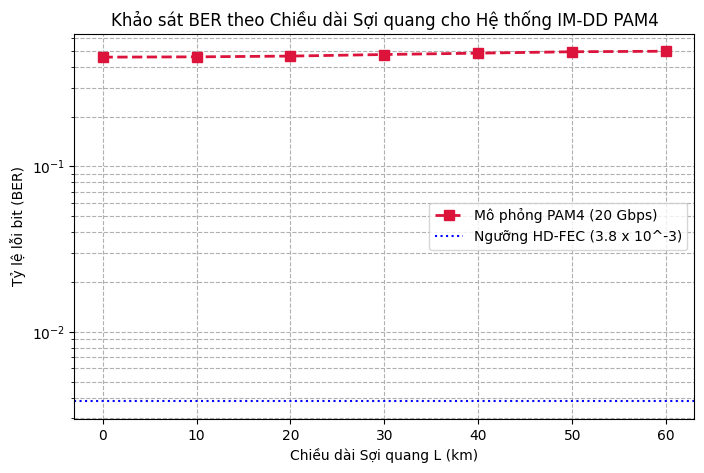

In [17]:
# --- KHẢO SÁT TỶ LỆ LỖI BIT (BER) THEO CỰ LY SỢI QUANG ---
print("\n--------------------------------------------------")
print("5. KHẢO SÁT TỶ LỆ LỖI BIT (BER) PAM4 THEO CỰ LY SỢI QUANG")
print("--------------------------------------------------")

L_vec = np.linspace(0, 60, 7)
BER_list = []

for L_i in L_vec:
    # 1. Truyền qua kênh sợi quang cự ly L_i
    H_fiber_i = np.exp(-alpha_m * (L_i * 1e3) / 2) * np.exp(1j * (beta2 / 2) * (omega**2) * (L_i * 1e3))
    E_rx_i = np.fft.ifft(np.fft.fft(E_tx) * H_fiber_i)
    
    # 2. Photodiode & Nhiễu
    I_dc_i = param.R * np.abs(E_rx_i)**2
    n_shot_i = np.random.normal(0, np.sqrt(2 * e * np.mean(I_dc_i) * param.B), N_samples)
    n_therm_i = np.random.normal(0, np.sqrt((4 * k * T_temp / R_load) * param.B), N_samples)
    
    # 3. Bộ lọc LPF
    I_filt_i = firFilter(h_lpf, I_dc_i + n_shot_i + n_therm_i)
    
    # 4. Lấy mẫu & Giải điều chế PAM4
    I_sampled = I_filt_i[0 :: param.SpS][:len(symbTx)]
    bitsRx_i = demodulateGray(I_sampled, 4, 'pam')
    
    # 5. Tính BER
    ber_i = np.mean(bitsTx != bitsRx_i)
    BER_list.append(max(ber_i, 1e-6)) # Đặt ngưỡng sàn 10^-6 phục vụ vẽ log scale

# Vẽ đồ thị đường cong BER theo cự ly truyền dẫn
plt.figure(figsize=(8, 5))
plt.semilogy(L_vec, BER_list, 's--', color='crimson', linewidth=2, markersize=7, label='Mô phỏng PAM4 (20 Gbps)')
plt.axhline(y=3.8e-3, color='blue', linestyle=':', label='Ngưỡng HD-FEC (3.8 x 10^-3)')
plt.xlabel('Chiều dài Sợi quang L (km)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title('Khảo sát BER theo Chiều dài Sợi quang cho Hệ thống IM-DD PAM4')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()